In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import os

import polars as pl
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

### Config

In [3]:
PROJECT_ROOT = Path(os.path.abspath(""))

DATA_PATH = PROJECT_ROOT / "data"

### Load data

In [4]:
def load_data(path: Path) -> pl.DataFrame:
    try:
        df = pl.read_parquet(path)
        print(f"file {path} successfully loaded")
        return df

    except FileNotFoundError:
        raise FileNotFoundError(
            f"File {path} not found, please run mle-process-data first to create preprocessed dataset"
        )


df = load_data(path=DATA_PATH / "games.parquet")

file /mnt/c/Workspace3/machine-learning-engineer-amsterdam (29)/data/games.parquet successfully loaded


### Split dataset

In [5]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

###  Feature set: use default features and MultiLabelBinarizer-encoded genre variables

In [6]:
DEFAULT_FEATURES = [
    "Price",
    "Required age",
    "Windows",
    "Mac",
    "Linux",
    "Achievements",
    "year",
]


def select_X_y(df, cols_x, cols_y) -> tuple[pl.DataFrame, pl.DataFrame]:
    """Select features and target from the dataframe."""
    return df.select(cols_x), df.get_column(cols_y)

In [7]:
X_cols = DEFAULT_FEATURES.copy()
X_cols += [
    c
    for c in df.columns
    if (
        c.startswith("genre_") and c != "genre_Free to Play"
    )  # free to plays are not included; price is relevant info
    or (c.startswith("tag_") and (c != "tag_Free to Play"))
    # free to plays are not included; price is relevant info
]
y_col = "target"

X_train, y_train = select_X_y(df_train, X_cols, y_col)
X_test, y_test = select_X_y(df_test, X_cols, y_col)

# to numpy
X_train, y_train = X_train.to_numpy(), y_train.to_numpy()
X_test, y_test = X_test.to_numpy(), y_test.to_numpy()

if not isinstance(
    X_train, np.ndarray
):  # without undersampling, it's not an array by def
    X_train = X_train.to_numpy()
if not isinstance(
    y_train, np.ndarray
):  # without undersampling, it's not an array by def
    y_train = y_train.to_numpy()

### Train a classifier and evaluate a classifier

train RMSE: 0.6390737523355745
test RMSE: 0.6771895497257646

                       precision    recall  f1-score   support

           0 - 20k EO       0.76      0.97      0.85      8308
        20k - 100k EO       0.40      0.15      0.22      2172
100k - 200 million EO       0.75      0.21      0.33      1243

             accuracy                           0.74     11723
            macro avg       0.64      0.44      0.47     11723
         weighted avg       0.69      0.74      0.68     11723



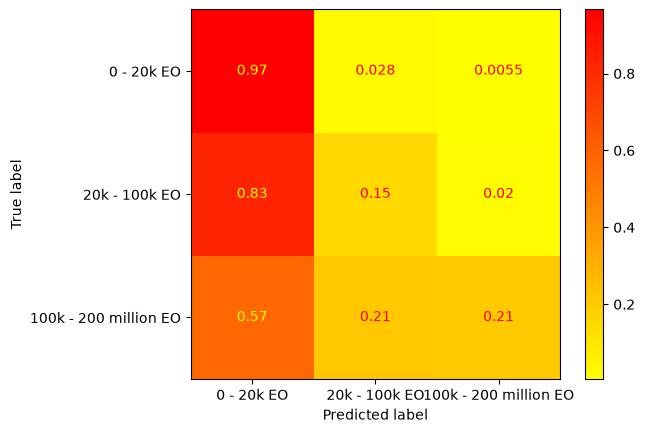

In [8]:
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier

# EO = estimated owners
TARGET_BINS = ["0 - 20k EO", "20k - 100k EO", "100k - 200 million EO"]

clf = KNeighborsClassifier()  # knn-classifier was found to be the best
clf.fit(X_train, y_train)

# check RMSE because classes are ordinal, so we want this to be as low as possible
print(f"train RMSE: {root_mean_squared_error(y_train, clf.predict(X_train))}")
print(f"test RMSE: {root_mean_squared_error(y_test, clf.predict(X_test))}\n")

# classification report
print(classification_report(y_test, clf.predict(X_test), target_names=TARGET_BINS))


# confusion matrix display
cmp = ConfusionMatrixDisplay.from_estimator(
    clf, X_test, y_test, cmap="autumn_r", normalize="true", display_labels=TARGET_BINS
)